In [ ]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

# Step 1: Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Step 2: Preprocess the data
# Reshape to include a channel dimension (28x28x1) and normalize pixel values
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

# Convert labels to one-hot encoding
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

# Step 3: Define the CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')  # Output layer for 10 classes (digits 0-9)
])

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Step 4: Train the model
history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_data=(x_test, y_test))

# Step 5: Evaluate the model
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Step 6: Save the trained model
model.save("mnist_digit_model.h5")
print("Model saved as 'mnist_model.h5'")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 59s 60ms/step - accuracy: 0.8875 - loss: 0.3728 - val_accuracy: 0.9808 - val_loss: 0.0588
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 79s 57ms/step - accuracy: 0.9845 - loss: 0.0519 - val_accuracy: 0.9869 - val_loss: 0.0377
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 52s 55ms/step - accuracy: 0.9895 - loss: 0.0337 - val_accuracy: 0.9863 - val_loss: 0.0387
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 52s 55ms/step - accuracy: 0.9932 - loss: 0.0231 - val_accuracy: 0.9887 - val_loss: 0.0337
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 53s 56ms/step - accuracy: 0.9944 - loss: 0.0186 - val_accuracy: 0.9891 - val_loss: 0.0334
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9860 - loss: 0.0423


Test Accuracy: 98.91%
Model saved as 'mnist_model.h5'


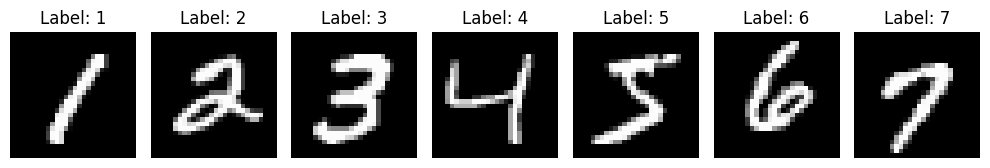

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Map to store the first occurrence of each digit from 1 to 7
digit_map = {i: None for i in range(1, 8)}

# Find the indices of digits 1 to 7 in the training set
for idx, label in enumerate(np.argmax(y_train, axis=1)):  # Convert one-hot to class indices
    if label in digit_map and digit_map[label] is None:
        digit_map[label] = idx
    if all(digit_map.values()):  # Stop if all digits are found
        break

# Plot the images
plt.figure(figsize=(10, 5))
for i, digit in enumerate(range(1, 8)):
    img_index = digit_map[digit]
    plt.subplot(1, 7, i + 1)
    plt.imshow(x_train[img_index].reshape(28, 28), cmap='gray')
    plt.title(f"Label: {digit}")
    plt.axis('off')

plt.tight_layout()
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step


<Figure size 1000x800 with 0 Axes>

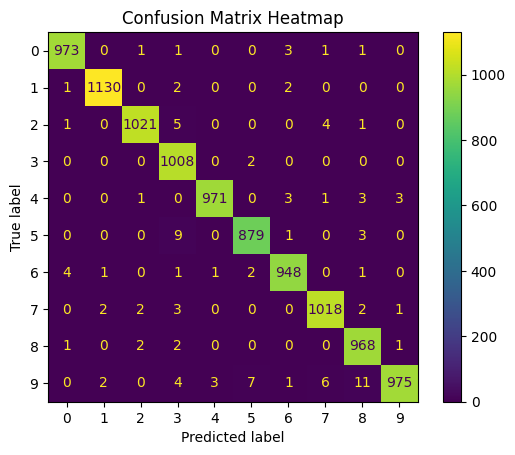

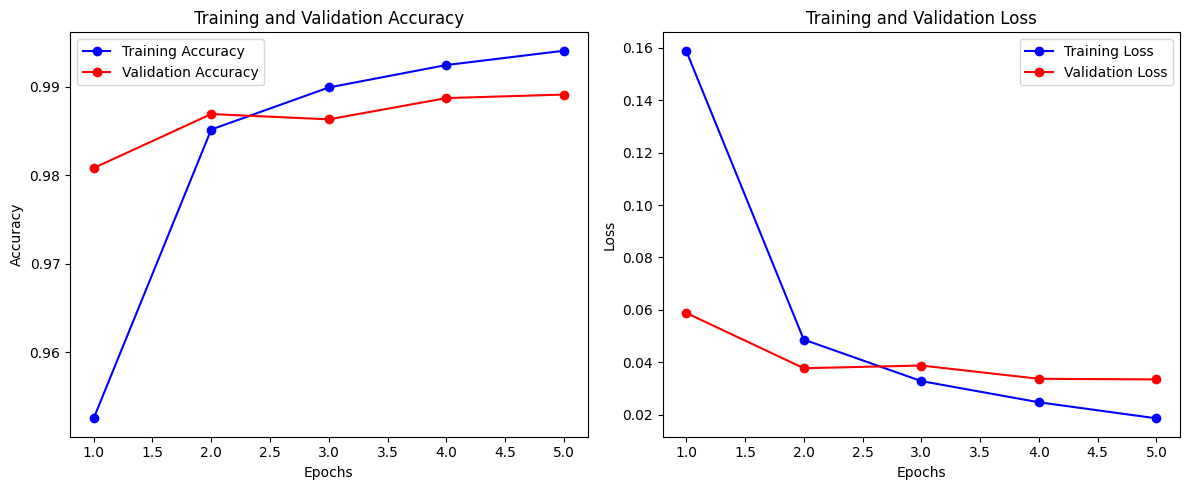

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Step 1: Predict the classes for the test dataset
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert predictions to class indices
y_true_classes = np.argmax(y_test, axis=1)  # Convert one-hot encoded labels to class indices

# Step 2: Create the confusion matrix
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

# Step 3: Plot the confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=np.arange(10))
disp.plot(cmap='viridis', values_format='d')
plt.title("Confusion Matrix Heatmap")
plt.show()

# Step 4: Plot training accuracy and loss
# Extract metrics from the history object
epochs = range(1, len(history.history['accuracy']) + 1)
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# Accuracy Plot
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, 'b-o', label="Training Accuracy")
plt.plot(epochs, val_accuracy, 'r-o', label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, 'b-o', label="Training Loss")
plt.plot(epochs, val_loss, 'r-o', label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()
